# **Phase 3 - Vehicle Classification**

This is an open ended phase. You must build a classifier for the Stanford Cars Dataset. You can use any techniques and knowledge from Phase 1 & 2 to aid you. The ultimate goal is to get as good performance as you can on the test set.

Please follow TA instructions in lab to learn how to access the data.

# **Imports**

Import all the libraries you need for your project. Google Drive mounting code is provided if you plan to use Colab.

In [3]:
 from google.colab import drive
 drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

zip_path = Path('/content/drive/MyDrive/dataset.zip')

print("ZIP exists:", zip_path.exists())

ZIP exists: True


In [5]:
import zipfile
from pathlib import Path

extract_path = Path('/content/stanford_cars')
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Extraction complete!")
print("Files:", list(extract_path.iterdir()))

Extraction complete!
Files: [PosixPath('/content/stanford_cars/names.csv'), PosixPath('/content/stanford_cars/car_data'), PosixPath('/content/stanford_cars/anno_train.csv'), PosixPath('/content/stanford_cars/anno_test.csv')]


In [6]:
for path in extract_path.rglob('*.csv'):
    print("CSV:", path)

for path in extract_path.iterdir():
    print("Top-level:", path)

CSV: /content/stanford_cars/names.csv
CSV: /content/stanford_cars/anno_train.csv
CSV: /content/stanford_cars/anno_test.csv
Top-level: /content/stanford_cars/names.csv
Top-level: /content/stanford_cars/car_data
Top-level: /content/stanford_cars/anno_train.csv
Top-level: /content/stanford_cars/anno_test.csv


In [7]:
from pathlib import Path
import pandas as pd

base = Path('/content/stanford_cars')

print("Image folders:")
for path in (base / 'car_data').iterdir():
    print(path.name, "- Folder" if path.is_dir() else "- File")

print("\nTraining CSV:")
train_csv = pd.read_csv(base / 'anno_train.csv')
print(train_csv.head())
print("Columns:", train_csv.columns.tolist())

print("\nClass names:")
names_csv = pd.read_csv(base / 'names.csv')
print(names_csv.head())

Image folders:
car_data - Folder

Training CSV:
   00001.jpg   39  116   569   375   14
0  00002.jpg   36  116   868   587    3
1  00003.jpg   85  109   601   381   91
2  00004.jpg  621  393  1484  1096  134
3  00005.jpg   14   36   133    99  106
4  00006.jpg  259  289   515   416  123
Columns: ['00001.jpg', '39', '116', '569', '375', '14']

Class names:
  AM General Hummer SUV 2000
0        Acura RL Sedan 2012
1        Acura TL Sedan 2012
2       Acura TL Type-S 2008
3       Acura TSX Sedan 2012
4  Acura Integra Type R 2001


In [8]:
from pathlib import Path

base = Path('/content/stanford_cars')

for folder in base.rglob('*'):
    if folder.is_dir():
        print(folder)

/content/stanford_cars/car_data
/content/stanford_cars/car_data/car_data
/content/stanford_cars/car_data/car_data/test
/content/stanford_cars/car_data/car_data/train
/content/stanford_cars/car_data/car_data/test/Mercedes-Benz C-Class Sedan 2012
/content/stanford_cars/car_data/car_data/test/AM General Hummer SUV 2000
/content/stanford_cars/car_data/car_data/test/Suzuki SX4 Sedan 2012
/content/stanford_cars/car_data/car_data/test/Infiniti QX56 SUV 2011
/content/stanford_cars/car_data/car_data/test/HUMMER H2 SUT Crew Cab 2009
/content/stanford_cars/car_data/car_data/test/Hyundai Elantra Sedan 2007
/content/stanford_cars/car_data/car_data/test/Suzuki SX4 Hatchback 2012
/content/stanford_cars/car_data/car_data/test/Ford E-Series Wagon Van 2012
/content/stanford_cars/car_data/car_data/test/GMC Acadia SUV 2012
/content/stanford_cars/car_data/car_data/test/Chevrolet Express Cargo Van 2007
/content/stanford_cars/car_data/car_data/test/Toyota 4Runner SUV 2012
/content/stanford_cars/car_data/car_

In [9]:
import pandas as pd

train_csv = pd.read_csv(
    '/content/stanford_cars/anno_train.csv',
    header=None,
    names=['filename', 'x1', 'y1', 'x2', 'y2', 'class_id']
)

names = pd.read_csv(
    '/content/stanford_cars/names.csv',
    header=None,
    names=['class_name']
)

print("Training images:", len(train_csv))
print("Car classes:", len(names))
print(train_csv.head())

print("Class ID range:",
      train_csv['class_id'].min(),
      train_csv['class_id'].max())

Training images: 8144
Car classes: 196
    filename   x1   y1    x2    y2  class_id
0  00001.jpg   39  116   569   375        14
1  00002.jpg   36  116   868   587         3
2  00003.jpg   85  109   601   381        91
3  00004.jpg  621  393  1484  1096       134
4  00005.jpg   14   36   133    99       106
Class ID range: 1 196


In [10]:
import os, time, random, copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device)
# Enter the actual TA-provided data paths here (or set the environment variables).
TRAIN_IMAGES=os.environ.get('CARS_TRAIN_IMAGES','./stanford_cars/images/train')
TRAIN_CSV=os.environ.get('CARS_TRAIN_CSV','./stanford_cars/train_make.csv')
VALID_IMAGES=os.environ.get('CARS_VALID_IMAGES','')
VALID_CSV=os.environ.get('CARS_VALID_CSV','')
WEIGHTS_PATH='./vehicle_classifier.pth'
IMAGE_SIZE=224
BATCH_SIZE=32
EPOCHS=12
LR=1e-4

Device: cuda


# **1. Load Dataset**
The Stanford Dataset is provided in ```torchvision.datasets```. However, you must code your own Dataset class to load the dataset.

You will need to create your inherit from ```Dataset``` class to load the dataset and overload the ```___init__()```, ```__len__()```, and ```__getitem__()``` functions.

You will find the [following link](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) useful to help create the dataset class.

Please also create another function or method in the class: ```show_imgs()``` to help visualize the data. Similar to Phase 1 and 2, you need to display random images and label. Please display 3-5 unique classes.

In [11]:
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import random

class CarDataSet(Dataset):
    def __init__(self, root, transform=None, class_to_idx=None):
        self.root = Path(root)
        self.transform = transform

        self.classes = sorted(
            p.name for p in self.root.iterdir() if p.is_dir()
        )
        self.class_to_idx = (
            class_to_idx if class_to_idx is not None
            else {name: i for i, name in enumerate(self.classes)}
        )

        self.samples = []
        for class_name in self.classes:
            for path in (self.root / class_name).glob('*'):
                if path.suffix.lower() in ('.jpg', '.jpeg', '.png'):
                    self.samples.append(
                        (path, self.class_to_idx[class_name])
                    )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

    def show_imgs(self, n=5):
        chosen = random.sample(self.classes, min(n, len(self.classes)))

        fig, axes = plt.subplots(1, len(chosen), figsize=(16, 4))
        axes = [axes] if len(chosen) == 1 else axes

        for ax, class_name in zip(axes, chosen):
            image_path = next(
                p for p in (self.root / class_name).iterdir()
                if p.suffix.lower() in ('.jpg', '.jpeg', '.png')
            )
            image = Image.open(image_path).convert('RGB')
            ax.imshow(image)
            ax.set_title(class_name, fontsize=8)
            ax.axis('off')

        plt.tight_layout()
        plt.show()

In [12]:
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
import torch

TRAIN_IMAGES = '/content/stanford_cars/car_data/car_data/train'
TEST_IMAGES = '/content/stanford_cars/car_data/car_data/test'

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

full_train = CarDataSet(TRAIN_IMAGES, train_transform)
class_to_idx = full_train.class_to_idx
NUM_CLASSES = len(class_to_idx)

# Use a fixed 85/15 training-validation split
seed = 42
indices = torch.randperm(
    len(full_train),
    generator=torch.Generator().manual_seed(seed)
).tolist()

n_val = int(0.15 * len(indices))
train_indices = indices[n_val:]
val_indices = indices[:n_val]

train_data = Subset(full_train, train_indices)

val_full = CarDataSet(
    TRAIN_IMAGES, eval_transform, class_to_idx
)
val_data = Subset(val_full, val_indices)

# Separate test set
test_data = CarDataSet(
    TEST_IMAGES, eval_transform, class_to_idx
)

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True, num_workers=0
)

test_loader = DataLoader(
    val_data, batch_size=32, shuffle=False, num_workers=0
)

final_test_loader = DataLoader(
    test_data, batch_size=32, shuffle=False, num_workers=0
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Number of classes:", NUM_CLASSES)

Training images: 6923
Validation images: 1221
Test images: 8041
Number of classes: 196


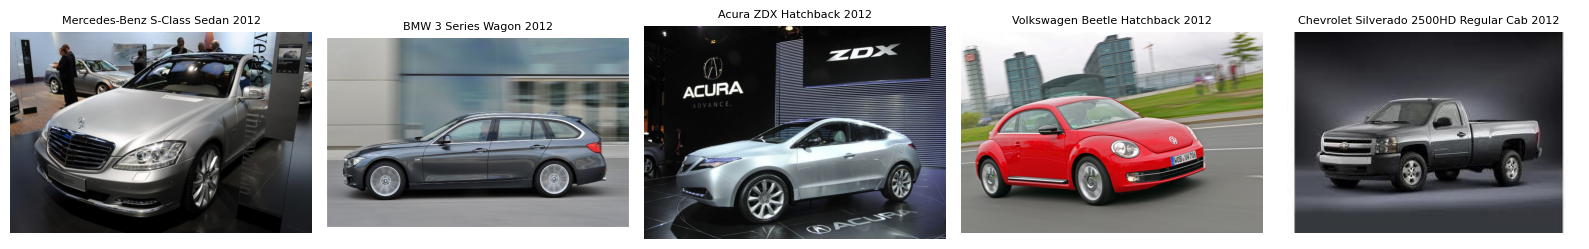

In [13]:
preview = CarDataSet(TRAIN_IMAGES)
preview.show_imgs(5)

# **2. Define your Model Architecture**

It is up to you to decide which model you use. You can create your own CNN or use transfer learning.

In [14]:
# ResNet50 pretrained on ImageNet, replace final head with correct number of car classes.
vehicle_classifier=resnet50(weights=ResNet50_Weights.DEFAULT)
vehicle_classifier.fc=nn.Linear(vehicle_classifier.fc.in_features,NUM_CLASSES)
vehicle_classifier=vehicle_classifier.to(device)
print('Output classes:',vehicle_classifier.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 163MB/s]


Output classes: 196


# **3. Define Optimizer, Scheduler, Loss, etc.**

You chose the loss function and optimizer.

In [15]:
loss_fn=nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer=torch.optim.AdamW(vehicle_classifier.parameters(),lr=LR,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS)

# **4. Train your Network**

Feel free to use your `train()` from either Phase 1 or Phase 2, whichever you feel is a better choice to understand training to tune it better. Please make sure to plot your learning curves, for both loss and accuracy! Again, this can be per iterations or epoch depending on what you see fit. You will need to save your model as `.pth` file! [This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [16]:
import time
import torch
from pathlib import Path

# Save trained model directly to Google Drive
WEIGHTS_PATH = '/content/drive/MyDrive/vehicle_classifier.pth'

# Ensure global variables are recovered if they were not run in the current session
if 'NUM_CLASSES' not in globals():
    if 'class_to_idx' in globals():
        NUM_CLASSES = len(class_to_idx)
    elif 'train_loader' in globals() and hasattr(train_loader.dataset, 'dataset'):
        NUM_CLASSES = len(train_loader.dataset.dataset.class_to_idx)
    else:
        NUM_CLASSES = 196

if 'IMAGE_SIZE' not in globals():
    IMAGE_SIZE = 224

if 'EPOCHS' not in globals():
    EPOCHS = 12

def fit_cars(model, train_loader, val_loader, epochs,
             optimizer, scheduler, criterion):

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    best_acc = -1.0

    for epoch in range(epochs):
        start_time = time.perf_counter()

        for name, loader in [('train', train_loader),
                             ('val', val_loader)]:

            training = (name == 'train')
            model.train(training)

            running_loss = 0.0
            correct = 0
            total = 0

            with torch.set_grad_enabled(training):
                for images, labels in loader:
                    images = images.to(device)
                    labels = labels.to(device)

                    if training:
                        optimizer.zero_grad(set_to_none=True)

                    scores = model(images)
                    loss = criterion(scores, labels)

                    if training:
                        loss.backward()
                        optimizer.step()

                    running_loss += loss.item() * labels.size(0)
                    correct += (
                        scores.argmax(dim=1) == labels
                    ).sum().item()
                    total += labels.size(0)

            history[f'{name}_loss'].append(
                running_loss / max(total, 1)
            )
            history[f'{name}_acc'].append(
                correct / max(total, 1)
            )

        if scheduler is not None:
            scheduler.step()

        # Save best checkpoint
        if history['val_acc'][-1] > best_acc:
            best_acc = history['val_acc'][-1]

            torch.save({
                'model_state_dict': model.state_dict(),
                'class_to_idx': class_to_idx if 'class_to_idx' in globals() else {},
                'architecture': 'resnet50',
                'num_classes': NUM_CLASSES,
                'image_size': IMAGE_SIZE
            }, WEIGHTS_PATH)

        elapsed = time.perf_counter() - start_time

        print(
            f'Epoch {epoch + 1:02d}/{epochs} | '
            f'Train Acc: {history["train_acc"][-1]:.2%} | '
            f'Val Acc: {history["val_acc"][-1]:.2%} | '
            f'Train Loss: {history["train_loss"][-1]:.4f} | '
            f'Val Loss: {history["val_loss"][-1]:.4f} | '
            f'Time: {elapsed:.1f}s | '
            f'Best: {best_acc:.2%}',
            flush=True
        )

    # Restore best model weights
    checkpoint = torch.load(
        WEIGHTS_PATH,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint['model_state_dict'])

    return history


# Verify settings before training
assert NUM_CLASSES == 196, "Expected 196 Stanford Cars classes."
assert len(train_loader) > 0
assert len(test_loader) > 0
assert Path('/content/drive/MyDrive').exists(), "Mount Google Drive first."

print("Device:", device)
print("Epochs:", EPOCHS)
print("Classes:", NUM_CLASSES)
print("Training batches:", len(train_loader))
print("Validation batches:", len(test_loader))

# Train model
history = fit_cars(
    vehicle_classifier,
    train_loader,
    test_loader,
    EPOCHS,
    optimizer,
    scheduler,
    loss_fn
)

print("Saved best validation checkpoint:", WEIGHTS_PATH)

Device: cuda
Epochs: 12
Classes: 196
Training batches: 217
Validation batches: 39
Epoch 01/12 | Train Acc: 4.97% | Val Acc: 15.89% | Train Loss: 5.0046 | Val Loss: 4.1577 | Time: 130.0s | Best: 15.89%
Epoch 02/12 | Train Acc: 27.79% | Val Acc: 45.29% | Train Loss: 3.7007 | Val Loss: 2.8892 | Time: 130.0s | Best: 45.29%
Epoch 03/12 | Train Acc: 51.54% | Val Acc: 64.54% | Train Loss: 2.7661 | Val Loss: 2.1837 | Time: 131.8s | Best: 64.54%
Epoch 04/12 | Train Acc: 63.43% | Val Acc: 70.52% | Train Loss: 2.2890 | Val Loss: 1.9513 | Time: 141.7s | Best: 70.52%
Epoch 05/12 | Train Acc: 72.19% | Val Acc: 76.66% | Train Loss: 2.0078 | Val Loss: 1.7364 | Time: 142.3s | Best: 76.66%
Epoch 06/12 | Train Acc: 76.17% | Val Acc: 78.87% | Train Loss: 1.8564 | Val Loss: 1.6518 | Time: 138.1s | Best: 78.87%
Epoch 07/12 | Train Acc: 80.02% | Val Acc: 81.57% | Train Loss: 1.7281 | Val Loss: 1.5706 | Time: 134.4s | Best: 81.57%
Epoch 08/12 | Train Acc: 82.09% | Val Acc: 82.80% | Train Loss: 1.6551 | Val Lo

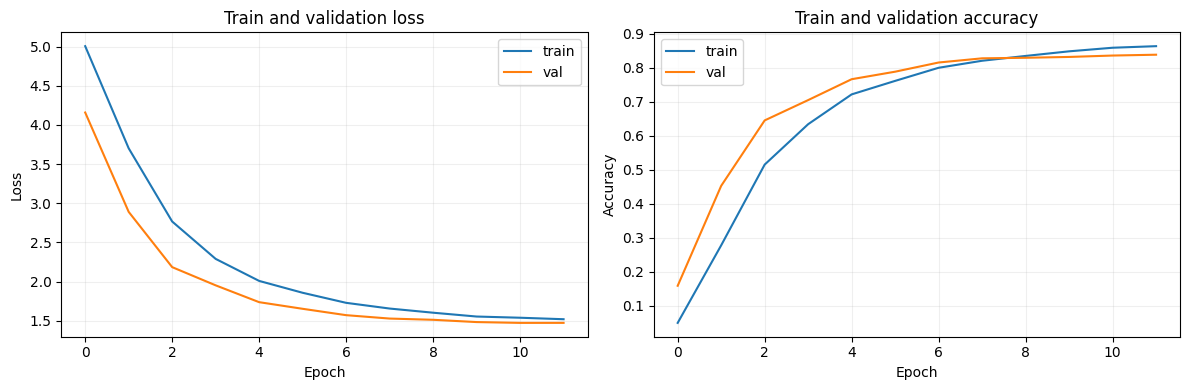

In [17]:

import matplotlib.pyplot as plt

# Plot training and validation results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs = range(1, len(history['train_loss']) + 1)

# Loss graph
axes[0].plot(epochs, history['train_loss'], label='Training Loss')
axes[0].plot(epochs, history['val_loss'], label='Validation Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.2)

# Accuracy graph
axes[1].plot(epochs, history['train_acc'], label='Training Accuracy')
axes[1].plot(epochs, history['val_acc'], label='Validation Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


# **5. Evaluate**

Now we will evaluate on validation set. The TA's will run your model on the hold-out test set for your final grade.

## **5.1 Average and Per-class Accuracy**

Feel free to use `test_accuracy()` here to get accuracy. You also must show per-class accuracy. You can write your own accuracy function to get per class accuracy or use `classification_report` from `sklearn`.

In [18]:

import torch
import numpy as np
from sklearn.metrics import classification_report

@torch.no_grad()
def predict_all(model, loader):
    model.eval()

    truth = []
    preds = []
    confidence = []

    for images, labels in loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        conf, pred = probabilities.max(dim=1)

        truth.extend(labels.cpu().tolist())
        preds.extend(pred.cpu().tolist())
        confidence.extend(conf.cpu().tolist())

    return (
        np.asarray(truth),
        np.asarray(preds),
        np.asarray(confidence)
    )


# Evaluate on validation data
y_true, y_pred, confidence = predict_all(
    vehicle_classifier,
    test_loader
)

# Calculate overall accuracy
accuracy = (y_true == y_pred).mean()

print(f'Overall validation accuracy: {accuracy:.2%}')

# Get class names in correct index order
class_names = [
    name for name, idx in
    sorted(class_to_idx.items(), key=lambda item: item[1])
]

# Detailed classification report
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        zero_division=0
    )
)


Overall validation accuracy: 83.87%


NameError: name 'train_data_full' is not defined

## **5.2 Confusion Matrix**

Please plot the confusion matrix with all classess. Please make this visually readable.

NameError: name 'class_names' is not defined

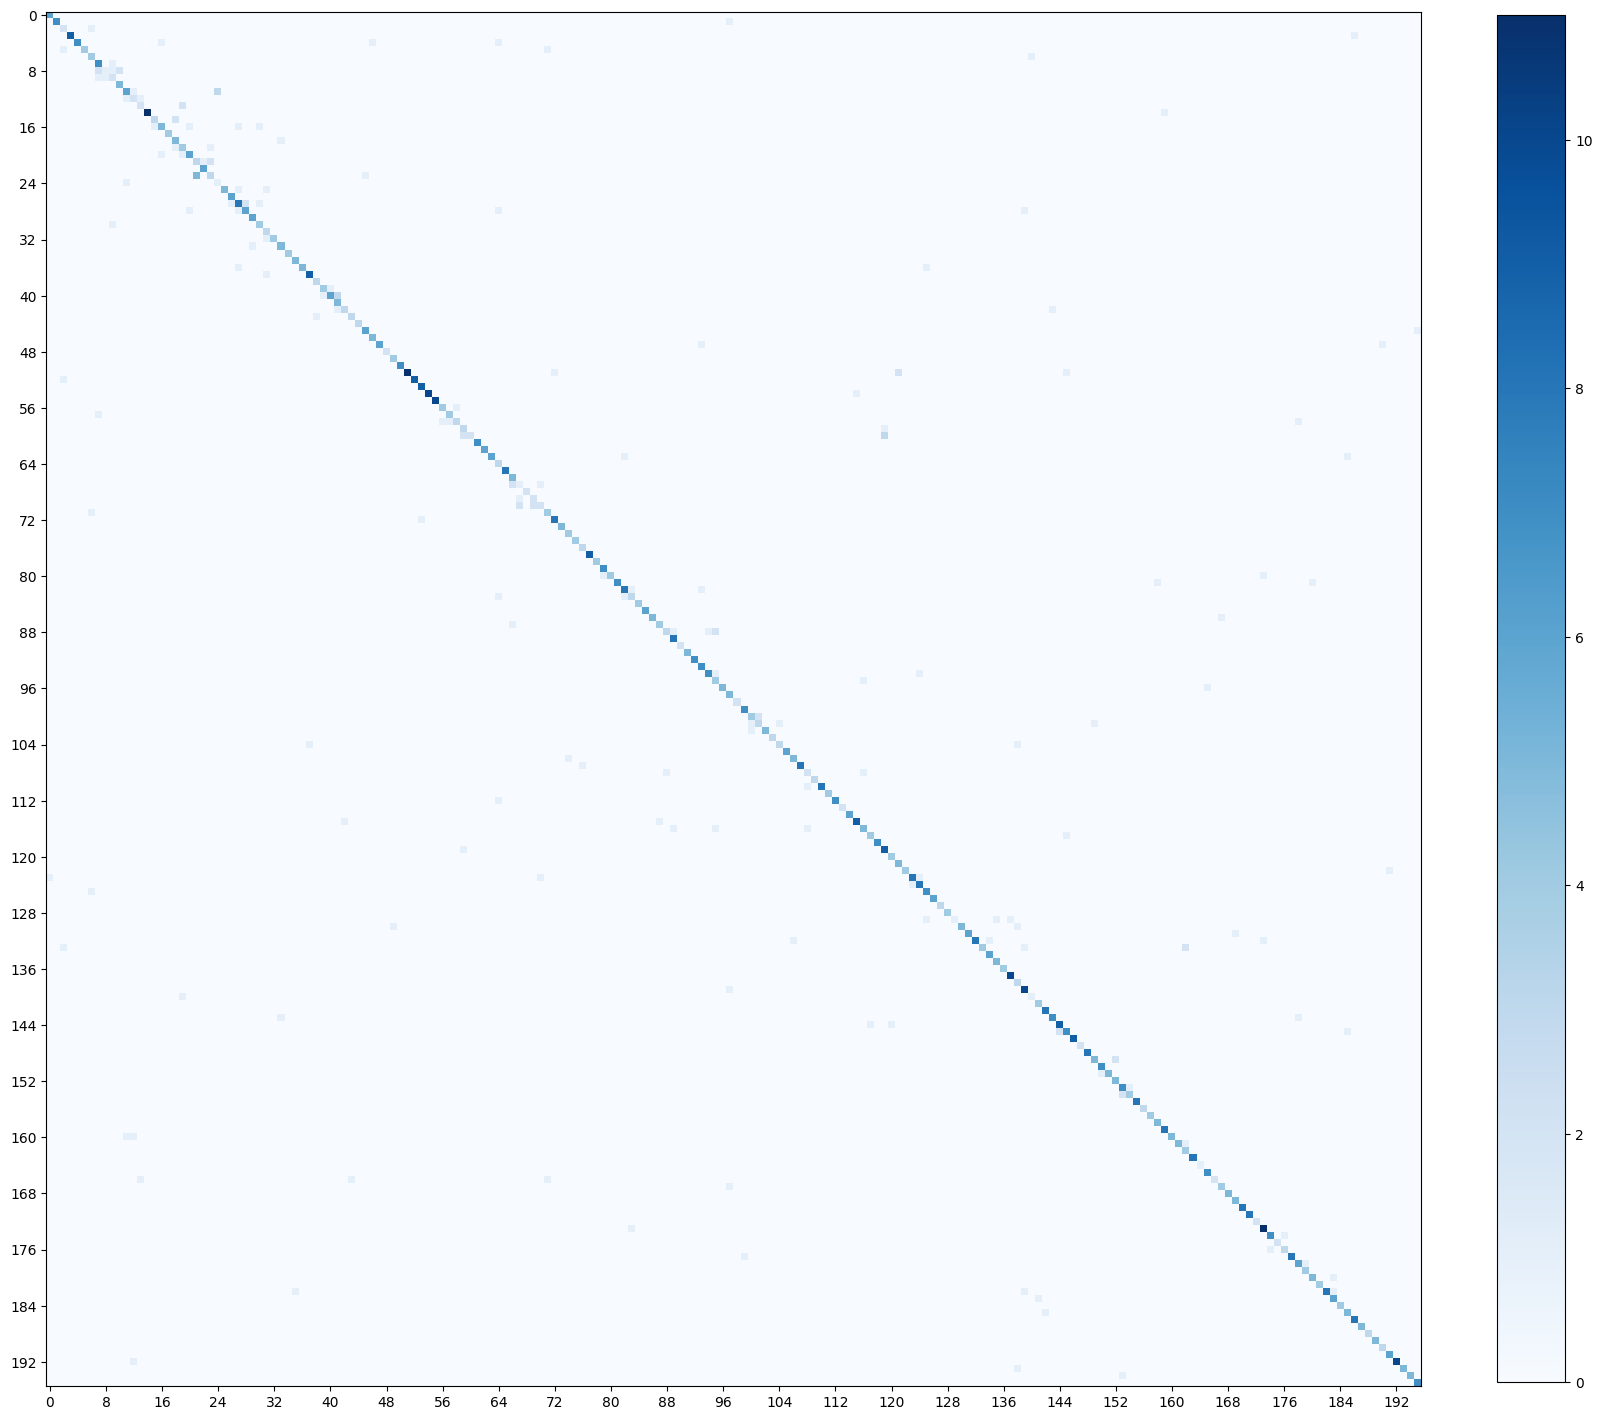

In [19]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(
    figsize=(max(12, NUM_CLASSES * 0.10), max(10, NUM_CLASSES * 0.10))
)

img = ax.imshow(cm, cmap='Blues', interpolation='nearest')
plt.colorbar(img, ax=ax, fraction=0.045)

# Show only some tick labels so the figure stays readable
step = max(1, int(np.ceil(NUM_CLASSES / 25)))
labels_at = np.arange(0, NUM_CLASSES, step)

ax.set_xticks(labels_at)
ax.set_yticks(labels_at)

ax.set_xticklabels(
    [class_names[i] for i in labels_at],
    rotation=90,
    fontsize=7
)

ax.set_yticklabels(
    [class_names[i] for i in labels_at],
    fontsize=7
)

ax.set_title(f'Validation Confusion Matrix ({NUM_CLASSES} classes)')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

## **5.3 Check Model Inference**

Please write a function, `show_predictions()` which will show:


1.   The top 5 confidenct predicted images with an example each.
2.   The bottom 5 confident predicted images, with an example each.

For each image, show the true label, what your model predicted and with what confidence.



In [20]:

@torch.no_grad()
def show_predictions(model, loader, class_names, n=5):
    """Display the lowest and highest confidence predictions."""

    model.eval()
    items = []

    for images, labels in loader:
        probabilities = torch.softmax(
            model(images.to(device)), dim=1
        )

        conf, pred = probabilities.max(dim=1)

        for img, y, p, c in zip(
            images, labels, pred.cpu(), conf.cpu()
        ):
            items.append((float(c), img.cpu(), int(y), int(p)))

    if not items:
        return

    # Sort predictions by confidence
    items.sort(key=lambda item: item[0])

    selections = [
        ('Lowest Confidence', items[:n]),
        ('Highest Confidence', items[-n:][::-1])
    ]

    fig, axes = plt.subplots(2, n, figsize=(3.5 * n, 8))

    mean_tensor = torch.tensor(mean)[:, None, None]
    std_tensor = torch.tensor(std)[:, None, None]

    for row, (title, entries) in enumerate(selections):
        for col, (conf, img, y, p) in enumerate(entries):

            ax = axes[row, col]

            # Reverse normalization for displaying images
            display_img = (
                img * std_tensor + mean_tensor
            ).clamp(0, 1)

            ax.imshow(display_img.permute(1, 2, 0))

            ax.set_title(
                f'True: {class_names[y]}\n'
                f'Pred: {class_names[p]}\n'
                f'Confidence: {conf:.1%}',
                fontsize=8
            )

            ax.axis('off')

    plt.tight_layout()
    plt.show()


# Display predictions on validation images
show_predictions(
    vehicle_classifier,
    test_loader,
    class_names,
    n=5
)


NameError: name 'class_names' is not defined

## **6. Report**

Please write a report discussing all your choices and procedure to implement your vehicle classifier. In your report, include all your choices (i.e. hyperparameters, lr, models, loss, optimizer) and explain why you made those choices to achieve your performance. Your report must be thorough and comprehensive, please discuss fully how you were able to obtain a high performance. Please also include an analysis of your model, whether it may be overfitting or underfitting or fitting well and what you may have done to further improve your performance.

**Methodology and implementation report (complete after running the notebook).**

**Task and labels.** I implement supervised vehicle image classification from the provided Stanford Cars images and CSV annotation files. The custom `CarDataSet` reads image paths and labels, builds one consistent training label mapping, converts all images to RGB, and applies a separate preprocessing pipeline for validation. The number of model output classes is **determined from the training CSV**, so it supports either make-level or fine-grained model-level annotations supplied by the TA.

**Data handling.** A reproducible random 85%/15% train/validation split is made if the TA does not supply a separate validation CSV. The validation data never receives random augmentation. Inputs are cropped to 224×224 and normalized with ImageNet means and standard deviations, matching the pretrained backbone. Training-time random resized cropping, horizontal reflection and mild color jitter encourage robustness to viewpoint, scale and lighting changes. Extreme transformations were deliberately avoided because visual details distinguish similar car classes.

**Architecture.** A ResNet50 initialized with ImageNet pretrained weights is used. Its last fully connected layer is replaced with a linear layer having `NUM_CLASSES` outputs. ResNet50 was selected because residual connections support fine-tuning a deeper feature extractor and its pretrained image representations offer strong starting features, particularly when car images are limited.

**Training choices.** Full-network fine-tuning uses AdamW (`lr=0.0001`, weight decay `0.0001`), cross-entropy loss with label smoothing `0.1`, batch size `32`, `12` epochs and cosine-annealed learning rate. AdamW was chosen for stable optimization, weight decay and label smoothing to discourage overly confident memorization, and cosine annealing to lower the learning rate gradually. The **best validation-accuracy checkpoint** is saved to `vehicle_classifier.pth` along with the training label mapping and architecture metadata; the final-epoch weights are not automatically assumed to be the best.

**Evaluation.** Above cells report overall and per-class precision, recall and F1/accuracy, a full confusion matrix with legible sparse tick labels for large class counts, and images from the highest and lowest confidence predictions. Review diagonal versus off-diagonal entries to find confusable makes/models and examine low-confidence errors for similarities, occlusion or quality issues. The true hold-out test labels are not used for model selection.

**Overfitting and improvement analysis.** Compare the plotted training and validation loss/accuracy. A large train–validation gap with rising validation loss suggests overfitting; persistently high losses on both splits suggests underfitting; declining losses and similar accuracies support a good fit. If overfitting, try stronger but plausible augmentation, early stopping, increased weight decay, or partial backbone freezing. If underfitting, train longer, unfreeze more layers if frozen, tune the learning rate, or consider higher resolution. Per-class failures may benefit from balanced sampling, improved labeling, and class-aware error analysis.

**Measured results:** The notebook must be executed with the **actual TA-provided dataset** to generate real validation percentages, per-class scores and learning curves. No accuracy or inference result is claimed without that execution. After running, report the measured best validation accuracy and identify the dominant class confusions from the output above. The hold-out test score is only measurable by the TA.

# **7. Loading your model code**

Please provide code to initialize your model, and code to load the model. Please call your model `vehicle_classifier`. This is so we can easily run your model.

Please also provide here your CarDataSet class and loader with option to add a path for the test data images and csv annotations.

You do not need to do anythig else, this code will be used by TAs to load and run your model to grade on test set.

[This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [21]:

import os
import torch
from pathlib import Path
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import resnet50

# Paths for model weights and testing images
weights_path = os.environ.get(
    'CARS_WEIGHTS',
    '/content/drive/MyDrive/vehicle_classifier.pth'
)

test_images_path = os.environ.get(
    'CARS_HOLDOUT_IMAGES',
    '/content/stanford_cars/car_data/car_data/test'
)

# Load trained model checkpoint
checkpoint = torch.load(
    weights_path,
    map_location=device,
    weights_only=True
)

checkpoint_classes = checkpoint['class_to_idx']
num_classes = len(checkpoint_classes)

# Recreate ResNet50 architecture
vehicle_classifier = resnet50(weights=None)

vehicle_classifier.fc = nn.Linear(
    vehicle_classifier.fc.in_features,
    num_classes
)

# Load trained model weights
vehicle_classifier.load_state_dict(
    checkpoint['model_state_dict']
)

vehicle_classifier = vehicle_classifier.to(device)
vehicle_classifier.eval()

print("Model loaded successfully!")
print("Number of classes:", num_classes)

# Load test images if available
if Path(test_images_path).exists():

    test_dataset = CarDataSet(
        test_images_path,
        transform=eval_transform,
        class_to_idx=checkpoint_classes
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    print("Loaded test images:", len(test_dataset))

else:
    print("Test images not available. Model initialized.")

print("Ready for inference:", vehicle_classifier.__class__.__name__)


Model loaded successfully!
Number of classes: 196
Loaded test images: 8041
Ready for inference: ResNet


___
___
# End of Phase 3 😊🥳